In [6]:
from pathlib import Path
import csv
import heapq
import math
import sys
from itertools import count
import matplotlib.pyplot as plt
from IPython.display import display, clear_output

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'johnson.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Open the notebook from the project folder containing johnson.py.')
sys.path.insert(0, str(ROOT))
import johnson as solver
print('Using', solver.__file__)
try:
    import ipywidgets as widgets
except ImportError:
    widgets = None

Using /Users/aayush/Desktop/DSA/Graph_Routing_Project 8.19.08 PM/johnson.py


In [7]:
def demo(cycle):
    nodes = [0, 1, 2, 3]
    edges = [(0,1,-2), (1,2,-1), (2,0,4), (0,3,3), (2,3,1)]
    inf = math.inf
    matrix = [[0,-2,-3,-2], [3,0,-1,0], [4,2,0,1], [inf,inf,inf,0]]
    if cycle:
        edges.append((2,1,-2))
        matrix[:3] = [[-inf]*4 for _ in range(3)]
    return nodes, edges, {(u,v): matrix[u][v] for u in nodes for v in nodes}

def choose_data():
    folder = ROOT / 'Datasets'
    paths = sorted(p for p in folder.glob('*') if p.is_file() and p.suffix.lower()=='.csv')
    print('Dataset folder:', folder)
    for i, path in enumerate(paths, 1):
        print(f'{i}. {path.name}')
    print('D = four-node demo    C = negative-cycle demo')
    while True:
        raw = input('File number, CSV path, D or C: ').strip().strip('"')
        if raw.upper() in ('D','C'):
            cycle = raw.upper() == 'C'
            return ('demo_cycle' if cycle else 'demo_four'), demo(cycle)
        path = paths[int(raw)-1] if raw.isdigit() and 1 <= int(raw) <= len(paths) else Path(raw).expanduser()
        if not path.is_file() and (folder/path).is_file():
            path = folder/path
        if path.is_file():
            return path.stem, solver.read_dataset(path)
        print('Select an available file or demo.')

def ask_node(label, nodes, default):
    while True:
        raw = input(f'{label} [{default}]: ').strip() or str(default)
        if raw.isdecimal() and int(raw) in nodes:
            return int(raw)
        print('Enter an ID listed in the dataset.')

In [8]:
def number(value):
    if value == math.inf: return '∞'
    if value == -math.inf: return '−∞'
    return f'{value:g}'

def replay(nodes, edges, start, goal):
    frames = []
    detailed = len(nodes) <= 12 and len(edges) <= 40
    h = dict.fromkeys(nodes, 0)
    def record(title, note, values, **details):
        frames.append(dict(title=title, note=note, values=dict(values), **details))
    record('Bellman–Ford · initialize', 'Zero-cost super-source edges give every vertex potential 0.', h)
    for i in range(len(nodes)-1):
        changed = False
        for u,v,w in edges:
            candidate = h[u] + w
            if candidate < h[v]:
                old = h[v]
                h[v] = candidate
                changed = True
                if detailed:
                    record(f'Bellman–Ford · pass {i+1}', f'{u} → {v}: h({v}) changes from {old} to {candidate}.', h, active=(u,v))
        if not changed or (not detailed and (i+1)%max(1,len(nodes)//20)==0):
            note = 'No potential changed. Check for a negative cycle.' if not changed else 'End of pass.'
            record(f'Bellman–Ford · pass {i+1}',note,h)
        if not changed: break
    for u,v,w in edges:
        if h[u]+w < h[v]:
            record('Negative Cycle Detected',f'{u} → {v} still permits a decrease after {len(nodes)-1} passes. Stop here.',h,active=(u,v))
            return frames, None
    adjacency = {u:[] for u in nodes}
    weights = {}
    for u,v,w in edges:
        rw = w+h[u]-h[v]
        assert rw >= 0
        weights[u,v] = rw
        adjacency[u].append((v,rw))
        if detailed:
            record('Reweight the edges', f'{u} → {v}: {w} + ({h[u]}) − ({h[v]}) = {rw}.', h, active=(u,v), weights=dict(weights))
    record('Reweighting complete','All edge weights are now nonnegative.',h,weights=weights)
    dist=dict.fromkeys(nodes,math.inf)
    dist[start]=0
    queue=[(0,start)]
    settled=set()
    while queue:
        cost,u=heapq.heappop(queue)
        if cost!=dist[u]: continue
        settled.add(u)
        updates=[]
        for v,w in adjacency[u]:
            if cost+w < dist[v]:
                dist[v]=cost+w
                heapq.heappush(queue,(dist[v],v))
                updates.append(f'{v}={dist[v]}')
        if detailed or len(settled)%max(1,len(nodes)//40)==0 or u==goal:
            note = 'Updated: '+', '.join(updates[:8]) if updates else 'No tentative distance improved.'
            record(f'Dijkstra · settle {u}',note,dist,weights=weights,settled=set(settled),current=u)
    restored={u:d-h[start]+h[u] for u,d in dist.items()}
    record('Restore original distances',f'd({start}, {goal}) = {number(dist[goal])} − ({h[start]}) + ({h[goal]}) = {number(restored[goal])}',restored,settled=settled)
    return frames,restored

In [9]:
def draw(step):
    frame=frames[step]
    fig,(ax,panel)=plt.subplots(1,2,figsize=(12,6),gridspec_kw={'width_ratios':[2,1]},facecolor='#f1f5f9')
    fig.suptitle(f'{dataset}   /   {frame["title"]}',color='#17263c',fontsize=18,fontweight='bold')
    positions={u:(math.cos(2*math.pi*i/len(nodes)),math.sin(2*math.pi*i/len(nodes))) for i,u in enumerate(nodes)}
    final=step==len(frames)-1
    route_edges=set(zip(route,route[1:])) if final else set()
    show_labels=len(nodes)<=20 and len(edges)<=65
    visible=edges if show_labels else edges[::max(1,math.ceil(len(edges)/500))]
    visible_pairs={(u,v) for u,v,_ in visible}
    if not show_labels:
        visible=visible+[e for e in edges if e[:2] in route_edges and e[:2] not in visible_pairs]
    for u,v,w in visible:
        a,b=positions[u],positions[v]
        active=(u,v)==frame.get('active')
        color='#d97706' if active else '#078569' if (u,v) in route_edges else '#94a3b8'
        bend=.16 if (v,u) in visible_pairs else 0
        ax.annotate('',xy=b,xytext=a,arrowprops=dict(arrowstyle='-|>',color=color,lw=2.6 if active or (u,v) in route_edges else .9,shrinkA=13 if show_labels else 2,shrinkB=13 if show_labels else 2,connectionstyle=f'arc3,rad={bend}'))
        if show_labels:
            label=frame.get('weights',{}).get((u,v),w)
            ax.text((a[0]+b[0])/2+bend*(b[1]-a[1])/2,(a[1]+b[1])/2-bend*(b[0]-a[0])/2,number(label),ha='center',va='center',bbox=dict(fc='white',ec='none',pad=1.4),fontsize=9)
    for u,(x,y) in positions.items():
        color='#078569' if final and u in route else '#2563a6' if u in frame.get('settled',()) else '#445770'
        ax.scatter(x,y,s=550 if show_labels else 12,c=color,zorder=4,edgecolors='#f59e0b' if u==frame.get('current') else 'white',linewidths=2)
        if show_labels: ax.text(x,y,str(u),color='white',ha='center',va='center',zorder=5,weight='bold')
    ax.set(xlim=(-1.25,1.25),ylim=(-1.25,1.25),aspect='equal')
    ax.axis('off');panel.axis('off')
    panel.text(0,.91,f'Step {step+1} of {len(frames)}',transform=panel.transAxes,color='#2563a6',weight='bold')
    from textwrap import fill
    panel.text(0,.80,fill(frame['note'],36),transform=panel.transAxes,va='top',fontsize=12,color='#15283f')
    value_label='Potentials' if frame['title'].startswith(('Bellman','Reweight','Negative')) else 'Distances from '+str(start)
    lines=[f'{u:>3}    {number(frame["values"][u])}' for u in nodes[:10]]
    if len(nodes)>10: lines.append('…')
    panel.text(0,.50,value_label,transform=panel.transAxes,weight='bold',color='#15283f')
    panel.text(0,.46,'\n'.join(lines),transform=panel.transAxes,va='top',family='monospace',fontsize=10,color='#15283f')
    fig.text(.06,.035,'Amber = active edge or node     Blue = settled     Green = final route',color='#334155')
    fig.tight_layout(rect=(0,.07,1,.94))
    return fig

def playback():
    if widgets is None:
        print('Manual playback: run view_step(1), view_step(2), etc.')
        return
    last=len(frames)
    slider=widgets.IntSlider(min=1,max=last,value=1,description='Step',continuous_update=False)
    play=widgets.Play(min=1,max=last,value=1,interval=2000)
    speed=widgets.Dropdown(options=[('1 second',1000),('2 seconds',2000),('3 seconds',3000),('5 seconds',5000)],value=2000,description='Delay')
    speed.observe(lambda change: setattr(play,'interval',change['new']),names='value')
    widgets.jslink((play,'value'),(slider,'value'))
    out=widgets.Output()
    def update(_=None):
        with out:
            clear_output(wait=True)
            view_step(slider.value)
    slider.observe(update,names='value')
    display(widgets.HBox([play,slider,speed]),out)
    update()

def view_step(step):
    if not 1 <= step <= len(frames): raise ValueError(f'Choose 1 through {len(frames)}.')
    fig=draw(step-1)
    plt.show()
    plt.close(fig)

Dataset folder: /Users/aayush/Desktop/DSA/Graph_Routing_Project 8.19.08 PM/Datasets
1. dataset1.csv
2. datset1.csv
D = four-node demo    C = negative-cycle demo
Enter an ID listed in the dataset.
Negative Cycle Detected
CSV cycle check: PASS


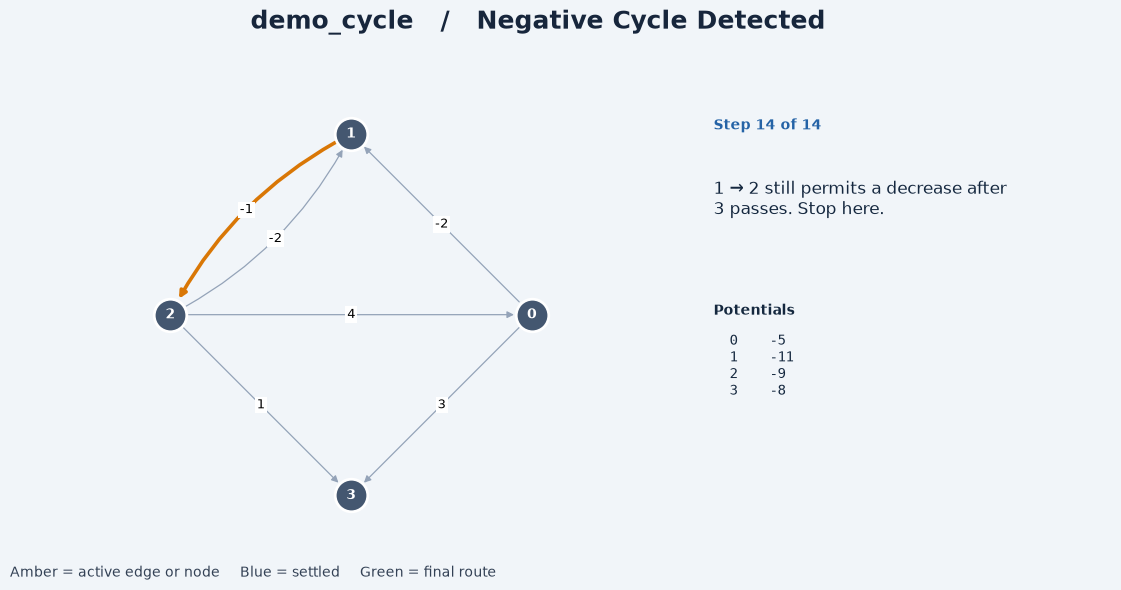

Saved /Users/aayush/Desktop/DSA/Graph_Routing_Project 8.19.08 PM/Images/demo_cycle_johnson_0_to_3.png


Output()

In [10]:
dataset,(nodes,edges,expected)=choose_data()
start=ask_node('Source',nodes,min(nodes))
goal=ask_node('Goal',nodes,max(nodes))
frames,replayed=replay(nodes,edges,start,goal)
route=[]
try:
    distances,parents=solver.johnson(nodes,edges)
except solver.NegativeCycleError:
    assert replayed is None
    print('Negative Cycle Detected')
    print('CSV cycle check:', 'PASS' if -math.inf in expected.values() else 'No matching cycle expectation')
else:
    assert replayed==distances[start], 'Replay and source module disagree.'
    route=solver.reconstruct_path(parents,start,goal)
    cost=distances[start][goal]
    weights={(u,v):w for u,v,w in edges}
    valid=(route[0]==start and route[-1]==goal and sum(weights[a,b] for a,b in zip(route,route[1:]))==cost) if route else cost==math.inf
    checked=sum(distances[u][v]==w for (u,v),w in expected.items())
    required=len(nodes)**2
    print('Route:', ' → '.join(map(str,route)) if route else 'unreachable')
    print('Cost:',number(cost),' | CSV expected:',number(expected[start,goal]) if (start,goal) in expected else 'not supplied')
    print(f'All-pairs verification: {checked}/{required} matched; {len(expected)} expected pairs supplied.')
    print('Overall:', 'PASS' if valid and checked==required else 'FAIL or incomplete reference')
    if len(nodes)<=12:
        print('Rows and columns:',nodes)
        for u in nodes: print(' '.join(f'{number(distances[u][v]):>5}' for v in nodes))
image_folder=ROOT/'Images'
image_folder.mkdir(exist_ok=True)
stem=f'{dataset}_johnson_{start}_to_{goal}'
destination=image_folder/(stem+'.png')
for i in count(2):
    if not destination.exists(): break
    destination=image_folder/f'{stem}_{i}.png'
fig=draw(len(frames)-1)
fig.savefig(destination,dpi=140,bbox_inches='tight')
plt.show()
plt.close(fig)
print('Saved',destination)
playback()